## Grafos y comunidades: Partición

- Tres maneras de partir el núcleo en comunidades disjuntas

- **Girvan–Newman** (quitar aristas puente), 

- **Espectral** (vectores propios del laplaciano) 

- **Louvain** (maximizar modularidad)

- Girvan–Newman solo corre sobre una muestra porque recalcula el betweenness de todas las aristas en cada paso

### Constantes

- `N_GN`: nodos de la muestra de Girvan–Newman

- `MAX_COM_GN`: hasta cuántas comunidades se sigue partiendo

- `K_MAX`: k máximo del barrido espectral

- `RANGO_GAMMA`: resoluciones de Louvain

- `SEMILLAS`: semillas para medir la estabilidad de Louvain

In [1]:
N_GN = 300                                   # tamaño de la muestra de Girvan–Newman
K_MAX = 40                                   # k máximo del barrido espectral
RANGO_GAMMA = [0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2.0, 3.0, 5.0, 10.0]
SEMILLAS = list(range(10))                   # antes 3 semillas
TOL_Q = 0.01                                 # candidatos: Q ≥ 99 % del máximo
EPS_EST = 0.01                               # diferencias de estabilidad menores se consideran empate

### Utilidades

In [2]:
NOTEBOOK = "b_particion"
%run ../funciones.ipynb
%run funciones.ipynb

In [3]:
spark = crear_spark(NOTEBOOK)
verificar_cluster(spark)

Master        : spark://spark-master:7077
Executors     : 2
Cores totales : 2
Memoria driver: 2.0 GB
UI del job    : http://localhost:4040


### Carga

In [4]:
config = leer_config()
n = config["n"]
v = pd.read_parquet(datos_dir / "nodos.parquet").sort_values("idx", ignore_index=True)
a = pd.read_parquet(datos_dir / "aristas.parquet")
A = matriz(a, n, config["peso"])
G = a_networkx(A)
tip = tipologia("proveedor", "proveedor_key").rename(columns={"proveedor_key": "clave"})[["clave", "tipologia"]]
v = v.merge(tip, on="clave", how="left")
v["tipologia"] = v.tipologia.fillna("esporádico (fuera del clustering)")
assert len(v) == n
print(f"núcleo: {n:,} nodos | {A.nnz // 2:,} aristas | peso = {config['peso']}")

núcleo: 7,114 nodos | 40,957 aristas | peso = peso


---
### **1. Modularidad de referencia**

- Q de particiones que no salen de la estructura

- Todo junto, cada nodo solo, por región, categoría, familia y tipología de KMeans

- Si un atributo ya diera Q alto, no haría falta buscar comunidades

In [5]:
SIN_DATO = {"SIN", "sin dato", "sin tipología", "esporádico (fuera del clustering)", "nan", "None"}

def por_atributo(col, sueltos=True):
    """sueltos=True: cada proveedor sin dato es su propia comunidad (no infla ni castiga la Q)."""
    s = v[col].astype("object")
    falta = (s.isna() | s.astype(str).isin(SIN_DATO)).to_numpy()
    lab = np.asarray(compactar(s.fillna("sin dato").astype(str))).copy()
    if sueltos and falta.any():
        lab[falta] = lab.max() + 1 + np.arange(falta.sum())
        lab = np.asarray(compactar(lab))
    return lab

referencias = {"todo junto": np.zeros(n, int), "cada nodo solo": np.arange(n),
               "región dominante": por_atributo("region_dom"), "categoría dominante": por_atributo("categoria_dom"),
               "familia dominante": por_atributo("familia_dom"), "tipología KMeans": por_atributo("tipologia"),
               "familia dominante (sin dato agrupado)": por_atributo("familia_dom", sueltos=False),
               "tipología KMeans (sin dato agrupado)": por_atributo("tipologia", sueltos=False)}
base = pd.DataFrame([resumir(A, lab, nombre) for nombre, lab in referencias.items()])
base[["metodo", "comunidades", "Q", "cobertura", "conductancia_med"]].round(3)

,metodo,comunidades,Q,cobertura,conductancia_med
0,todo junto,1,-0.000,1.000,0.000
1,cada nodo solo,7114,-0.001,0.000,NaN
2,región dominante,25,0.362,0.755,0.523
3,categoría dominante,3,0.431,0.963,0.061
4,familia dominante,2732,0.332,0.354,0.715
5,tipología KMeans,2807,0.079,0.487,0.710
6,familia dominante (sin dato agrupado),214,0.403,0.476,0.715
7,tipología KMeans (sin dato agrupado),5,0.104,0.544,0.696


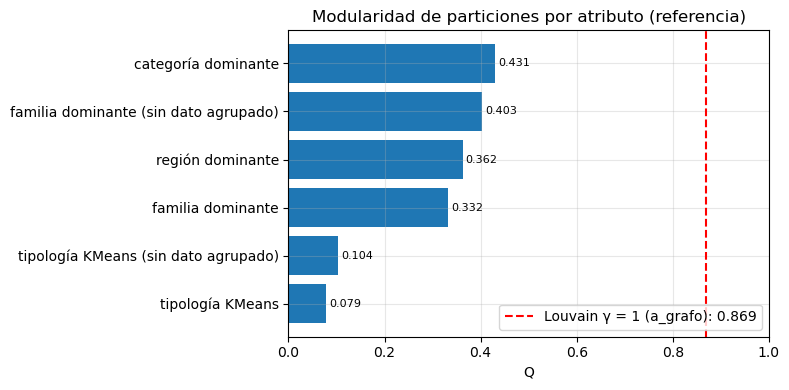

In [6]:
b_ = base[~base.metodo.isin(["todo junto", "cada nodo solo"])].sort_values("Q")   # triviales: Q ≈ 0
ep = pd.read_parquet(Path.cwd() / "temp" / "a_grafo" / "tablas" / "eleccion_peso")
q_lv = float(ep.loc[ep.peso == config["peso"], "Q"].iloc[0])
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(b_.metodo, b_.Q)
ax.bar_label(ax.containers[0], fmt="%.3f", fontsize=8, padding=2)
ax.axvline(q_lv, ls="--", c="red", label=f"Louvain γ = 1 (a_grafo): {q_lv:.3f}")
ax.set(xlabel="Q", xlim=(0, 1), title="Modularidad de particiones por atributo (referencia)"); ax.legend(loc="lower right")
mostrar_fig("q_referencias")

- **Región dominante:** Q **0.362** con 25 grupos: la geografía agrupa parte de la competencia

- **Categoría** (Q **0.431**) supera a la región con solo 3 grupos y conductancia mediana 0.06

- **Familia** (Q **0.332** con los sin dato sueltos, **0.403** agrupados)

- **Tipología KMeans** (Q **0.079** / **0.104**): la tipología describe el perfil del proveedor, no con quién compite

---
### **2. Girvan–Newman**

- **Muestra:** 4 comunidades vecinas de Louvain (γ = 1), ~(`N_GN` / 4) nodos de cada una

- **Betweenness sin pesos** (default de networkx): con pesos, el camino más corto trataría `peso` como distancia

In [7]:
lab_ref_nucleo = np.asarray(louvain(a_networkx(A), 1.0))       
muestra, elegidas = muestra_comunidades(A, lab_ref_nucleo, N_GN)
MAX_COM_GN = max(30, 3 * len(elegidas))
A_m = A[muestra][:, muestra]
G_m = a_networkx(A_m)
t0 = time.time(); niveles = girvan_newman_q(G_m, A_m, MAX_COM_GN); seg_gn = time.time() - t0
gn = pd.DataFrame([{k: x[k] for k in ("comunidades", "Q", "seg")} for x in niveles])
mejor_gn = max(niveles, key=lambda x: x["Q"])
lab_lv_m = louvain(G_m)
lab_ref_m = compactar(lab_ref_nucleo[muestra])

gn_vs_lv = pd.DataFrame([resumir(A_m, mejor_gn["lab"], "girvan-newman (muestra)", mejor_gn["seg"]),
                         resumir(A_m, lab_lv_m, "louvain (muestra)"),
                         resumir(A_m, lab_ref_m, "referencia (núcleo restringido)")])
labs_m = (mejor_gn["lab"], lab_lv_m, lab_ref_m)
gn_vs_lv["nmi_vs_ref"] = [nmi(l_, lab_ref_m) for l_ in labs_m]
gn_vs_lv["ari_vs_ref"] = [ari(l_, lab_ref_m) for l_ in labs_m]
gn_vs_lv["nmi_gn_lv"], gn_vs_lv["ari_gn_lv"] = nmi(mejor_gn["lab"], lab_lv_m), ari(mejor_gn["lab"], lab_lv_m)
print(f"muestra: {len(muestra)} nodos de {len(elegidas)} comunidades vecinas, {A_m.nnz // 2} aristas | "
      f"{len(gn)} niveles en {seg_gn:.1f} s | tope {MAX_COM_GN} comunidades")
gn_vs_lv.round(3)

muestra: 300 nodos de 4 comunidades vecinas, 2360 aristas | 29 niveles en 23.8 s | tope 30 comunidades


,metodo,comunidades,comunidades_grandes,pct_nodos_en_mayor,pct_nodos_en_grandes,Q,cobertura,conductancia_med,seg,nmi_vs_ref,ari_vs_ref,nmi_gn_lv,ari_gn_lv
0,girvan-newman (muestra),5,5,25.000,100.0,0.545,0.961,0.029,21.949,0.923,0.908,0.901,0.887
1,louvain (muestra),4,4,26.333,100.0,0.551,0.966,0.027,NaN,0.955,0.964,0.901,0.887
2,referencia (núcleo restringido),4,4,25.000,100.0,0.547,0.971,0.024,NaN,1.000,1.000,0.901,0.887


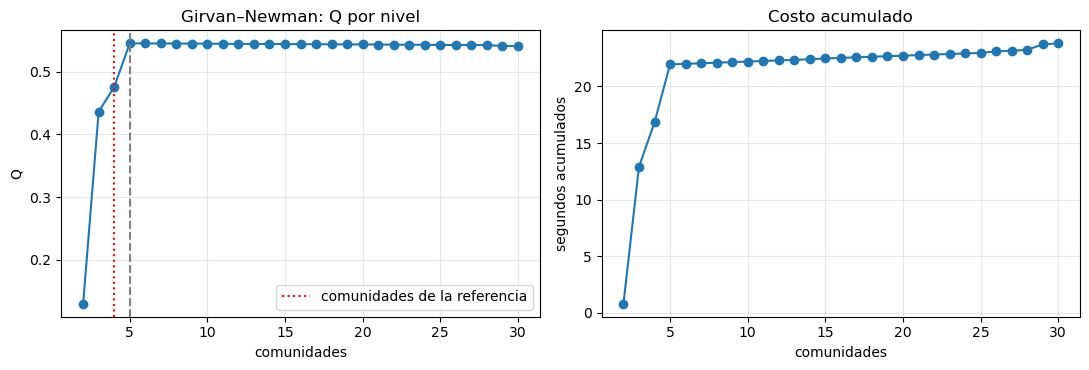

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(gn.comunidades, gn.Q, "o-"); ax[0].axvline(mejor_gn["comunidades"], ls="--", c="gray")
ax[0].set(xlabel="comunidades", ylabel="Q", title="Girvan–Newman: Q por nivel")
ax[0].axvline(len(elegidas), ls=":", c="red", label="comunidades de la referencia"); ax[0].legend()
ax[1].plot(gn.comunidades, gn.seg, "o-")
ax[1].set(xlabel="comunidades", ylabel="segundos acumulados", title="Costo acumulado")
mostrar_fig("girvan_newman")

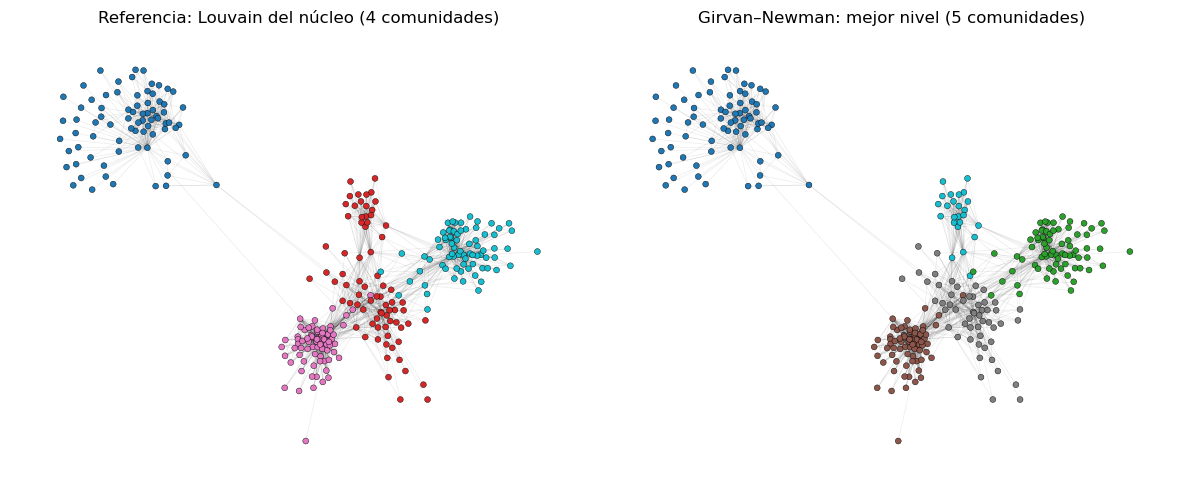

In [9]:
pos_m = nx.spring_layout(G_m, weight="weight", seed=SEED)
xy = np.array([pos_m[k] for k in range(len(muestra))])
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a_, lab_, tit in ((ax[0], lab_ref_m, f"Referencia: Louvain del núcleo ({len(elegidas)} comunidades)"),
                      (ax[1], mejor_gn["lab"], f"Girvan–Newman: mejor nivel ({mejor_gn['comunidades']} comunidades)")):
    nx.draw_networkx_edges(G_m, pos_m, ax=a_, alpha=.08, width=.5)
    a_.scatter(xy[:, 0], xy[:, 1], c=lab_, cmap="tab10", s=18, edgecolors="k", linewidths=.3, zorder=2)
    a_.set_title(tit); a_.axis("off")
mostrar_fig("girvan_newman_muestra")

- **Mejor nivel:** **5** comunidades, Q **0.545**; recupera las 4 de la referencia (NMI **0.92**, ARI **0.91**)

- **En el dibujo** la comunidad aislada (azul) es idéntica en ambos

- Girvan–Newman separa el centro denso en dos y corta distinto el borde entre las comunidades del centro

- **Louvain** en la misma muestra llega a Q **0.551** y coincide con Girvan–Newman (NMI **0.90**)

- **Costo:** **23 s** para **300 nodos** y 2,360 aristas; cada nivel recalcula el betweenness (O(n·m))

---
### **3. Espectral**

- **Laplaciano normalizado:** sus k primeros vectores propios embeben los nodos y KMeans los agrupa

$$L = I - D^{-1/2} A \, D^{-1/2}$$

- $A$: matriz de adyacencia con `peso`; $D$: matriz diagonal con la fuerza de cada nodo ($D_{ii} = \sum_j A_{ij}$); $I$: identidad

- **Eigengap:** un salto grande entre $\lambda_k$ y $\lambda_{k+1}$ sugiere k comunidades bien separadas

- Se barre k y se mide Q de cada partición

In [10]:
t0 = time.time(); val, vec = espectro(A, K_MAX + 1); seg_eig = time.time() - t0
filas = []
for k in range(2, K_MAX + 1):
    t0 = time.time(); lab = particion_espectral(vec, k); seg = time.time() - t0
    filas.append({**resumir(A, lab, f"espectral k={k}", seg + seg_eig), "k": k, "eigengap": val[k] - val[k - 1]})
esp = pd.DataFrame(filas)
k_qmax = int(esp.loc[esp.Q.idxmax(), "k"])
K_ESPECTRAL = int(esp[esp.Q >= esp.Q.max() * (1 - TOL_Q)].k.min())   # menor k con Q ≥ 99 % del máximo
k_gap = int(esp.loc[esp.eigengap.idxmax(), "k"])
lab_esp = particion_espectral(vec, K_ESPECTRAL)
print(f"λ₁ = {val[0]:.1e} | k con Q máxima = {k_qmax} (Q {esp.Q.max():.3f}) | "
      f"k elegido = {K_ESPECTRAL} (Q {esp.set_index('k').Q[K_ESPECTRAL]:.3f}) | "
      f"k por eigengap = {k_gap} | autovectores en {seg_eig:.1f} s")
esp[["k", "comunidades", "Q", "conductancia_med", "eigengap", "seg"]].round(4)

λ₁ = 5.6e-16 | k con Q máxima = 37 (Q 0.851) | k elegido = 28 (Q 0.843) | k por eigengap = 2 | autovectores en 3.1 s


,k,comunidades,Q,conductancia_med,eigengap,seg
0,2,2,0.0601,0.0241,0.0036,3.0786
1,3,3,0.5326,0.0137,0.0009,3.0804
2,4,4,0.6013,0.0183,0.0005,3.0817
3,5,5,0.6127,0.0145,0.0001,3.0822
4,6,6,0.7334,0.0202,0.0013,3.0834
5,7,7,0.7433,0.0261,0.0007,3.0868
6,8,8,0.7490,0.0241,0.0001,3.0946
7,9,9,0.7676,0.0233,0.0023,3.1230
8,10,10,0.7693,0.0251,0.0009,3.0950
9,11,11,0.7866,0.0268,0.0011,3.0980


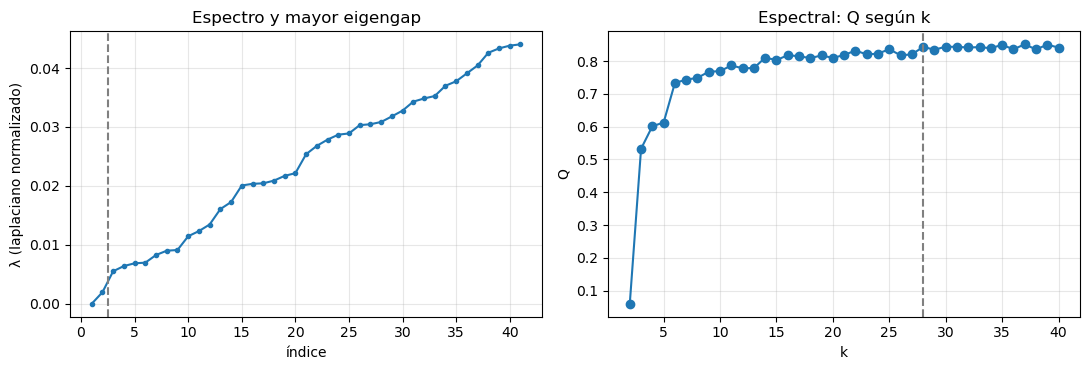

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(np.arange(1, len(val) + 1), val, "o-", ms=3); ax[0].axvline(k_gap + .5, ls="--", c="gray")
ax[0].set(xlabel="índice", ylabel="λ (laplaciano normalizado)", title="Espectro y mayor eigengap")
ax[1].plot(esp.k, esp.Q, "o-"); ax[1].axvline(K_ESPECTRAL, ls="--", c="gray")
ax[1].set(xlabel="k", ylabel="Q", title="Espectral: Q según k")
mostrar_fig("espectral")

- **λ₁ ≈ 0** (5.6e-16) confirma un núcleo conexo

- **Q máximo en k = 37** (Q **0.851**); se elige **k = 28**, el menor con Q ≥ 99% del máximo (Q **0.843**)

- **El eigengap sugiere k = 2**, pero todos los saltos son < 0.004: no hay un corte claro y manda Q

- KMeans en el embedding tiende a grupos de tamaño parecido: las comunidades chicas quedan absorbidas

---
### **4. Louvain**

Maximiza la modularidad con resolución γ:

$$Q_\gamma = \sum_c \left[ \frac{e_c}{2m} - \gamma \left( \frac{vol_c}{2m} \right)^2 \right]$$

- $e_c$: peso de las aristas dentro de la comunidad c (contado en ambos sentidos)

- $vol_c$: suma de las fuerzas (peso total) de los nodos de c

- $2m$: peso total del grafo (contado en ambos sentidos)

- $\gamma$: castiga el tamaño; γ > 1 da comunidades más chicas, γ < 1 más grandes

(1) cada nodo se mueve a la comunidad vecina que más sube Q_γ, hasta que ninguno mejora

(2) cada comunidad se colapsa en un nodo y se repite

- Para cada γ se corre con varias semillas: **estabilidad** = NMI medio entre pares de semillas

- `Q` se reporta siempre con γ = 1 para poder comparar

In [12]:
filas, part_gamma = [], {}
for g_ in RANGO_GAMMA:
    labs = []
    for s in SEMILLAS:
        t0 = time.time(); lab = louvain(G, g_, s); seg = time.time() - t0
        labs.append(lab)
        filas.append({**resumir(A, lab, "louvain", seg), "gamma": g_, "semilla": s})
    part_gamma[g_] = labs
lv = pd.DataFrame(filas)
estab = {g_: np.mean([nmi(x, y) for k_, x in enumerate(labs) for y in labs[k_ + 1:]]) for g_, labs in part_gamma.items()}
lv_g = (lv.groupby("gamma").agg(Q=("Q", "mean"), Q_sd=("Q", "std"), comunidades=("comunidades", "median"),
                                grandes=("comunidades_grandes", "median"), mayor=("pct_nodos_en_mayor", "median"),
                                conductancia=("conductancia_med", "median"), seg=("seg", "mean"))
          .assign(estabilidad=pd.Series(estab)))
lv_g.round(3)

,Q,Q_sd,comunidades,grandes,mayor,conductancia,seg,estabilidad
gamma,,,,,,,,
0.25,0.838,0.009,15.5,14.0,24.199,0.031,0.639,0.875
0.50,0.864,0.002,24.5,20.5,18.443,0.038,0.899,0.909
0.75,0.868,0.001,32.0,25.0,13.305,0.044,0.710,0.936
1.00,0.869,0.001,36.0,30.0,12.433,0.051,0.724,0.942
1.25,0.868,0.001,40.5,32.5,12.384,0.061,0.713,0.947
1.50,0.868,0.001,45.5,35.0,12.152,0.068,0.718,0.946
2.00,0.865,0.001,54.5,39.0,10.936,0.079,0.765,0.953
3.00,0.855,0.002,68.5,49.0,8.497,0.093,0.849,0.953
5.00,0.810,0.006,94.0,68.0,5.517,0.124,0.686,0.947


candidatos: [0.5, 0.75, 1.0, 1.25, 1.5, 2.0] → tras estabilidad: [1.25, 1.5, 2.0]
γ elegido = 1.25 | Q = 0.8701 | estabilidad = 0.947


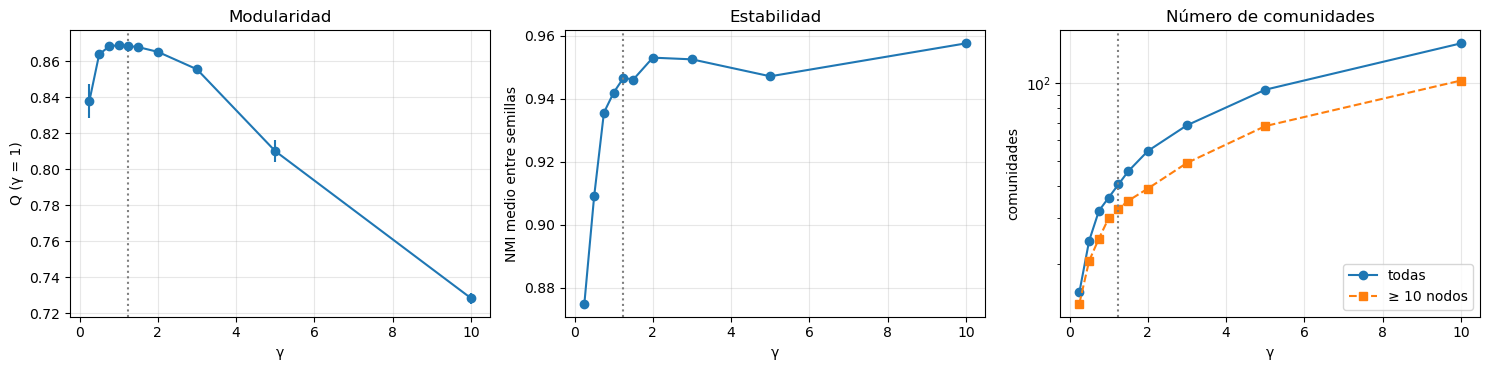

In [13]:
cand = lv_g[lv_g.Q >= lv_g.Q.max() * (1 - TOL_Q)]                   # Q dentro del 1 % del máximo
cand = cand[cand.estabilidad >= cand.estabilidad.max() - EPS_EST]   # empate de estabilidad si difiere < 0.01
GAMMA = float(cand.assign(g=cand.index).sort_values(["Q", "g"], ascending=[False, True]).index[0])
print(f"candidatos: {list(lv_g[lv_g.Q >= lv_g.Q.max() * (1 - TOL_Q)].index)} → tras estabilidad: {list(cand.index)}")
sub = lv[lv.gamma == GAMMA]
lab_lv = part_gamma[GAMMA][int(sub.Q.to_numpy().argmax())]
print(f"γ elegido = {GAMMA} | Q = {modularidad(A, lab_lv):.4f} | estabilidad = {estab[GAMMA]:.3f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].errorbar(lv_g.index, lv_g.Q, yerr=lv_g.Q_sd, fmt="o-"); ax[0].set(xlabel="γ", ylabel="Q (γ = 1)", title="Modularidad")
ax[1].plot(lv_g.index, lv_g.estabilidad, "o-"); ax[1].set(xlabel="γ", ylabel="NMI medio entre semillas", title="Estabilidad")
ax[2].plot(lv_g.index, lv_g.comunidades, "o-", label="todas")
ax[2].plot(lv_g.index, lv_g.grandes, "s--", label=f"≥ {MIN_TAM} nodos")
ax[2].set(xlabel="γ", ylabel="comunidades", yscale="log", title="Número de comunidades"); ax[2].legend()
for ax_ in ax:
    ax_.axvline(GAMMA, ls=":", c="gray")
mostrar_fig("louvain_gamma")

In [14]:
def q_nulo_config(A, gamma, reps=3, seed=0):
    n_ = A.shape[0]
    Gb = nx.Graph(); Gb.add_nodes_from(range(n_)); Gb.add_edges_from(a_networkx(A).edges())
    m_ = Gb.number_of_edges()
    qs = []
    for r_ in range(reps):
        H = Gb.copy()
        nx.double_edge_swap(H, nswap=5 * m_, max_tries=50 * m_, seed=seed + r_)
        lab_h = np.asarray(louvain(H, gamma))
        qs.append(nx.community.modularity(H, [set(np.flatnonzero(lab_h == c)) for c in np.unique(lab_h)]))
    return float(np.mean(qs)), float(np.std(qs))

Ab = A.copy(); Ab.data[:] = 1.0
q_real_bin = modularidad(Ab, np.asarray(louvain(a_networkx(Ab), GAMMA)))
q_nul, q_sd = q_nulo_config(A, GAMMA)
config.update({"q_real_binaria": q_real_bin, "q_nulo": q_nul, "q_nulo_sd": q_sd})
print(f"Q binaria real {q_real_bin:.3f} | nulo de configuración {q_nul:.3f} ± {q_sd:.3f}")

Q binaria real 0.854 | nulo de configuración 0.238 ± 0.001


- **γ elegido = 1.25:** Q dentro del 1% del máximo (γ de 0.5 a 2)

- **Q casi plano** entre γ = 0.5 y 2 (0.864–0.869): la partición no depende de afinar γ

- **Modelo nulo:** Q binaria real **0.854** frente a **0.238 ± 0.001** en grafos con los mismos grados

---
### **5. Comparación de métodos**

In [15]:
comparacion = pd.DataFrame([resumir(A, lab_lv, f"louvain γ={GAMMA}", sub.seg.mean()),
                            resumir(A, lab_esp, f"espectral k={K_ESPECTRAL}", esp.loc[esp.k == K_ESPECTRAL, "seg"].iloc[0])])
acuerdo = pd.DataFrame([{"par": "louvain vs espectral", "nmi": nmi(lab_lv, lab_esp), "ari": ari(lab_lv, lab_esp)}])
PRINCIPAL = "louvain" if comparacion.Q[0] >= comparacion.Q[1] else "espectral"
display(comparacion.round(3)); display(acuerdo.round(3))
print(f"partición principal: {PRINCIPAL}")

,metodo,comunidades,comunidades_grandes,pct_nodos_en_mayor,pct_nodos_en_grandes,Q,cobertura,conductancia_med,seg
0,louvain γ=1.25,41,34,12.314,99.410,0.870,0.930,0.059,0.713
1,espectral k=28,28,27,12.932,99.902,0.843,0.935,0.065,3.144


,par,nmi,ari
0,louvain vs espectral,0.821,0.703


partición principal: louvain


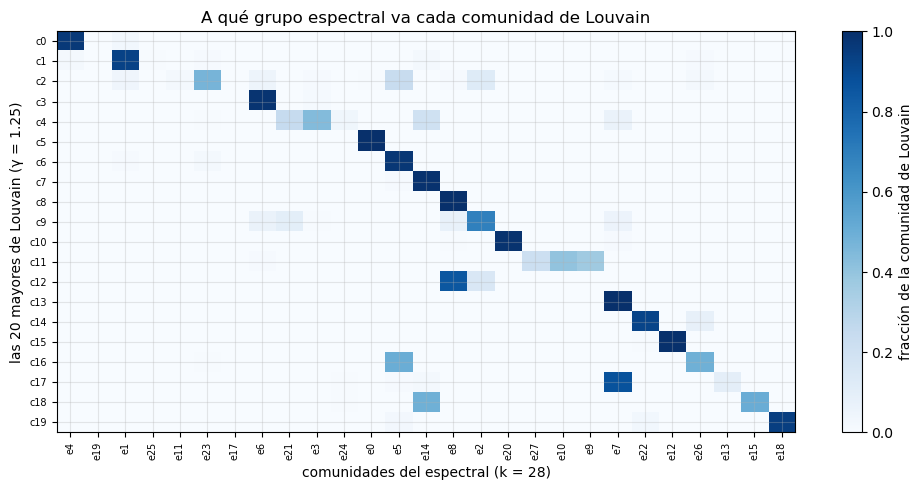

In [16]:
top_lv = np.argsort(-np.bincount(lab_lv))[:TOP_K]
frac = pd.crosstab(lab_lv, lab_esp, normalize="index").loc[top_lv]
frac = frac.loc[:, frac.sum() > 0]
orden = frac.idxmax(axis=0).map({r: k for k, r in enumerate(frac.index)}).sort_values().index
frac = frac[orden]
fig, ax = plt.subplots(figsize=(10, 5))
im = ax.imshow(frac.to_numpy(), aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(frac))); ax.set_yticklabels([f"c{c}" for c in frac.index], fontsize=7)
ax.set_xticks(range(frac.shape[1])); ax.set_xticklabels([f"e{c}" for c in frac.columns], fontsize=7, rotation=90)
ax.set(xlabel=f"comunidades del espectral (k = {K_ESPECTRAL})", ylabel=f"las {TOP_K} mayores de Louvain (γ = {GAMMA})",
       title="A qué grupo espectral va cada comunidad de Louvain")
plt.colorbar(im, ax=ax, label="fracción de la comunidad de Louvain")
mostrar_fig("louvain_vs_espectral")

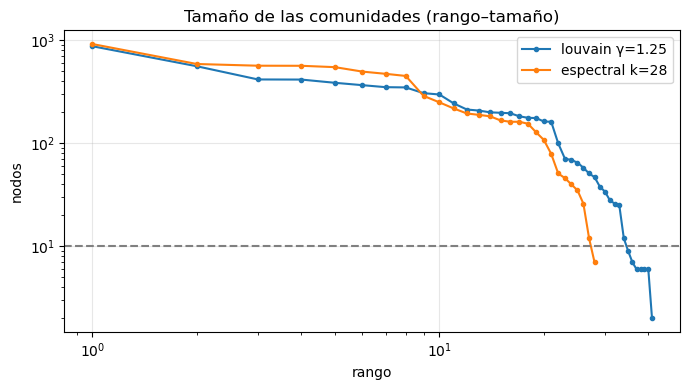

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))
for nombre, lab in ((f"louvain γ={GAMMA}", lab_lv), (f"espectral k={K_ESPECTRAL}", lab_esp)):
    t = np.sort(np.bincount(compactar(lab)))[::-1]
    ax.loglog(np.arange(1, len(t) + 1), t, "o-", ms=3, label=nombre)
ax.axhline(MIN_TAM, ls="--", c="gray")
ax.set(xlabel="rango", ylabel="nodos", title="Tamaño de las comunidades (rango–tamaño)"); ax.legend()
mostrar_fig("tamanos_comunidades")

- **Louvain** logra la mayor Q (**0.870** vs **0.843** del espectral) en 0.7 s (vs 13 s) 

- **Louvain** respeta una distribución de tamaños de cola pesada; el **espectral** reparte en k grupos parecidos

- **Acuerdo:** NMI **0.82** (ARI 0.70) entre Louvain y espectral

- **Donde difieren:** el espectral parte algunas comunidades de Louvain en 2–3 grupos y junta otras

- **Partición principal: Louvain γ = 1.25** (41 comunidades, 34 con ≥ 10 proveedores); el espectral queda como robustez

---
### **6. Exportación a `temp/datos/`**

- `particion.parquet`: idx, Louvain (γ elegido), espectral (k elegido)

- `particion_gamma_web`: comunidad de cada proveedor del núcleo para cada γ (semilla 0)

In [18]:
pd.DataFrame({"idx": np.arange(n), "louvain": lab_lv, "espectral": lab_esp}).to_parquet(datos_dir / "particion.parquet", index=False)
config.update({"gamma": GAMMA, "k_espectral": K_ESPECTRAL, "k_eigengap": k_gap, "principal": PRINCIPAL})
guardar_config(config)
web = pd.concat([pd.DataFrame({"clave": v.clave, "gamma": g_, "comunidad": labs[0]}) for g_, labs in part_gamma.items()],
                ignore_index=True)

---
### **7. Escritura de resultados**

In [19]:
escritos = guardar_tablas({"referencias": base, "girvan_newman": gn, "gn_vs_louvain": gn_vs_lv, "espectral": esp,
                           "louvain": lv, "louvain_gamma": lv_g.reset_index(), "comparacion": comparacion,
                           "acuerdo": acuerdo, "comunidades": por_comunidad(A, lab_lv), "particion_gamma_web": web})

Escrito en 05_Comunidad/temp/b_particion/: referencias, girvan_newman, gn_vs_louvain, espectral, louvain, louvain_gamma, comparacion, acuerdo, comunidades, particion_gamma_web


#### a. Verificación

In [20]:
verificar_salidas(escritos)
q_nx = nx.community.modularity(G, [set(np.flatnonzero(lab_lv == c)) for c in np.unique(lab_lv)], weight="weight")
assert abs(modularidad(A, lab_lv) - q_nx) < 1e-9, "Q propia ≠ networkx"
assert (lab_lv >= 0).all() and len(lab_lv) == n, "hay nodos sin comunidad"
print("Q propia = networkx | todos los nodos tienen comunidad")

OK: 10 tablas (parquet + json) | 7 figuras: espectral, girvan_newman, girvan_newman_muestra, louvain_gamma, louvain_vs_espectral, q_referencias, tamanos_comunidades
Q propia = networkx | todos los nodos tienen comunidad


---
### **8. Cerrar sesión**

In [21]:
spark.stop()